In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.gridding import interpolate_to_common_grid
from km5c.plotting import latdepthplot, shade_below_bathymetry
from km5c.paths import FIG_DIR, MODERN_D13C_PATH, MODERN_D18O_PATH, WOA23_TEMP_PATH
from km5c.proxies import comparison_tables

proxy = comparison_tables()
PLIOMIP2_d13C_comparison_table = proxy.PLIOMIP2_d13C_comparison_table
PLIOMIP2_d18O_comparison_table = proxy.PLIOMIP2_d18O_comparison_table

In [2]:
import pandas as pd
import numpy as np
import numpy.ma as ma # For masked arrays
import re # For regular expression parsing of the header
import xarray as xr # For easy conversion to N-dimensional arrays

# --- Configuration ---
# IMPORTANT: Ensure this path is correct for your system
csv_file_path = WOA23_TEMP_PATH
# --- End Configuration ---

# Initialize outputs to None
lat_coords = None
lon_coords = None
depth_coords = None
temperature_grid = None
temperature_grid_masked = None

try:
    # --- Step 1: Read the second line to extract depth information ---
    with open(csv_file_path, 'r') as f:
        f.readline()  # Skip the first comment line
        header_line_for_depths = f.readline()

    match = re.search(r'DEPTHS \(M\):(.+)', header_line_for_depths)
    if not match:
        print("Error: Could not find depth information in the CSV header's second line.")
        print("Expected format: '#COMMA SEPARATED LATITUDE, LONGITUDE, AND VALUES AT DEPTHS (M):0,5,10,...'")
    else:
        depth_strings = match.group(1).split(',')
        # Convert depth strings to float, stripping whitespace and handling potential empty strings
        parsed_depths = [float(d.strip()) for d in depth_strings if d.strip()]
        
        print(f"Parsed depths from header: {parsed_depths}") # Diagnostic print for depths
        if 0.0 not in parsed_depths:
            print("Warning: Depth 0.0 was not found in the parsed depths from the header.")
        else:
            print("Confirmed: Depth 0.0 is included in parsed depths.")


        # --- Step 2: Define column names ---
        column_names = ['latitude', 'longitude'] + parsed_depths

        # --- Step 3: Read the CSV data ---
        df = pd.read_csv(
            csv_file_path,
            comment='#',
            header=None,
            names=column_names,
            na_values=[''], # Treat empty strings (common for missing data) as NaN
            low_memory=False
        )

        # --- Step 4: Melt the DataFrame to long format ---
        df_long = pd.melt(
            df,
            id_vars=['latitude', 'longitude'],
            value_vars=parsed_depths, # Use the float versions of depths
            var_name='depth',
            value_name='temperature'
        )
        df_long['depth'] = pd.to_numeric(df_long['depth'])

        # --- Step 5: Prepare for 3D array conversion ---
        df_indexed = df_long.set_index(['depth', 'latitude', 'longitude'])
        df_indexed = df_indexed.sort_index() # Important for consistent xarray conversion

        # --- Step 6: Convert to xarray DataArray and then to NumPy arrays ---
        if not df_indexed.empty:
            xr_data_array = df_indexed['temperature'].to_xarray()

            temperature_grid = xr_data_array.data
            depth_coords = xr_data_array['depth'].data
            lat_coords = xr_data_array['latitude'].data
            lon_coords = xr_data_array['longitude'].data

            # --- Step 6b: Create a masked array for temperature, masking NaNs ---
            temperature_grid_masked = ma.masked_invalid(temperature_grid) # masks NaN and inf

            # --- Step 7: Display results and verify ---
            print("\nSuccessfully processed data into NumPy arrays.")
            print(f"Shape of 1D depth_coords array: {depth_coords.shape}")
            # print(f"Depth coordinates: {depth_coords}")
            
            print(f"\nShape of 1D lat_coords array: {lat_coords.shape}")
            # print(f"Latitude coordinates (first 5): {lat_coords[:5]}")

            print(f"\nShape of 1D lon_coords array: {lon_coords.shape}")
            # print(f"Longitude coordinates (first 5): {lon_coords[:5]}")

            print(f"\nShape of 3D temperature_grid (depth, latitude, longitude): {temperature_grid.shape}")
            
            print(f"\nShape of 3D temperature_grid_masked: {temperature_grid_masked.shape}")
            print(f"Number of masked values in temperature_grid_masked: {temperature_grid_masked.mask.sum() if isinstance(temperature_grid_masked.mask, np.ndarray) else 'No mask or all unmasked'}")
            print(f"Number of unmasked values: {temperature_grid_masked.count()}")


            # Example: Accessing a data point from the original and masked array
            d_idx, lt_idx, ln_idx = 0, 0, 0 
            if (temperature_grid.shape[0] > d_idx and
                temperature_grid.shape[1] > lt_idx and
                temperature_grid.shape[2] > ln_idx):
                example_temp = temperature_grid[d_idx, lt_idx, ln_idx]
                example_temp_masked = temperature_grid_masked[d_idx, lt_idx, ln_idx]
                print(f"\nExample: Temperature at depth {depth_coords[d_idx]}, lat {lat_coords[lt_idx]}, lon {lon_coords[ln_idx]}:")
                print(f"  Original value: {example_temp}")
                print(f"  Masked array value: {example_temp_masked} (type: {type(example_temp_masked)})")
                if ma.is_masked(example_temp_masked):
                    print("  This value is masked.")
            else:
                print("\nCould not retrieve example data point, grid might be smaller or indices out of bounds.")
        else:
            print("The DataFrame was empty after indexing, cannot create xarray object.")

except FileNotFoundError:
    print(f"Error: The file '{csv_file_path}' was not found. Please check the path.")
except pd.errors.EmptyDataError:
    print("Error: The CSV file is empty or no data could be read after skipping comments.")
except ImportError as e:
    print(f"Error: A required library is not installed. {e}. Please install it (e.g., pip install xarray).")
except Exception as e:
    print(f"An unexpected error occurred during processing: {e}")

# You can now use:
# lat_coords, lon_coords, depth_coords (1D NumPy arrays)
# temperature_grid (3D NumPy array with NaNs)
# temperature_grid_masked (3D NumPy masked array, NaNs are masked)

def prep_lat_depth_value(df, lat_candidates, depth_candidates, value_candidates, label):
    d = df.copy()
    d.columns = [str(c).strip() for c in d.columns]

    lat_col = pick_col(d, lat_candidates)
    dep_col = pick_col(d, depth_candidates)
    val_col = pick_col(d, value_candidates)

    if lat_col is None or dep_col is None or val_col is None:
        missing = []
        if lat_col is None:
            missing.append("latitude")
        if dep_col is None:
            missing.append("depth")
        if val_col is None:
            missing.append("value")
        raise KeyError(f"{label} missing required column(s): {', '.join(missing)}")

    out = pd.DataFrame({
        "lat": pd.to_numeric(d[lat_col], errors="coerce"),
        "depth": pd.to_numeric(d[dep_col], errors="coerce"),
        "value": pd.to_numeric(d[val_col], errors="coerce"),
    }).dropna(subset=["lat", "depth", "value"])

    return out



Parsed depths from header: [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0, 65.0, 70.0, 75.0, 80.0, 85.0, 90.0, 95.0, 100.0, 125.0, 150.0, 175.0, 200.0, 225.0, 250.0, 275.0, 300.0, 325.0, 350.0, 375.0, 400.0, 425.0, 450.0, 475.0, 500.0, 550.0, 600.0, 650.0, 700.0, 750.0, 800.0, 850.0, 900.0, 950.0, 1000.0, 1050.0, 1100.0, 1150.0, 1200.0, 1250.0, 1300.0, 1350.0, 1400.0, 1450.0, 1500.0, 1550.0, 1600.0, 1650.0, 1700.0, 1750.0, 1800.0, 1850.0, 1900.0, 1950.0, 2000.0, 2100.0, 2200.0, 2300.0, 2400.0, 2500.0, 2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0, 3600.0, 3700.0, 3800.0, 3900.0, 4000.0, 4100.0, 4200.0, 4300.0, 4400.0, 4500.0, 4600.0, 4700.0, 4800.0, 4900.0, 5000.0, 5100.0, 5200.0, 5300.0, 5400.0, 5500.0]
Confirmed: Depth 0.0 is included in parsed depths.

Successfully processed data into NumPy arrays.
Shape of 1D depth_coords array: (102,)

Shape of 1D lat_coords array: (168,)

Shape of 1D lon_coords array: (360,)

Shape of 

In [3]:
import netCDF4 as nc
import numpy as np

path = MODERN_D13C_PATH

modern_d13C_nc = nc.Dataset(path)

mo_lon = modern_d13C_nc.variables["lon"][:]
mo_lat = modern_d13C_nc.variables["lat"][:]
mo_depth = modern_d13C_nc.variables["depth"][:]
mo_d13C = modern_d13C_nc.variables["c13_mo"][:]

# Option 1: Using numpy.nan masking  (Recommended)
mo_d13C_masked = np.ma.masked_invalid(mo_d13C)  # Create a masked array

# If you need to convert back to a regular numpy array, replace NaNs with a fill value:
# mo_d13C_filled = np.nan_to_num(mo_d13C) # Replaces NaN with 0 or another safe value.  Be careful about the fill value.

# OR
# mo_d13C_filled = np.where(np.isnan(mo_d13C), np.nanmean(mo_d13C), mo_d13C)  #Replaces NaNs with the mean of the array


# Option 2:  Replace NaN values directly (Less Recommended if you want to retain masked array functionality)

# mo_d13C[np.isnan(mo_d13C)] = np.nanmean(mo_d13C) # Be very careful about the mean if there is a lot of missing data
# mo_d13C[np.isnan(mo_d13C)] = 0 # Replace missing values using 0



# Verify the masking
print("Original mo_d13C shape:", mo_d13C.shape)
print("Masked mo_d13C shape:", mo_d13C_masked.shape)
print("Number of NaN values in original array:", np.isnan(mo_d13C).sum())
print("Number of masked values in masked array:", mo_d13C_masked.mask.sum())


Original mo_d13C shape: (33, 180, 360)
Masked mo_d13C shape: (33, 180, 360)
Number of NaN values in original array: 1476778
Number of masked values in masked array: 1476778


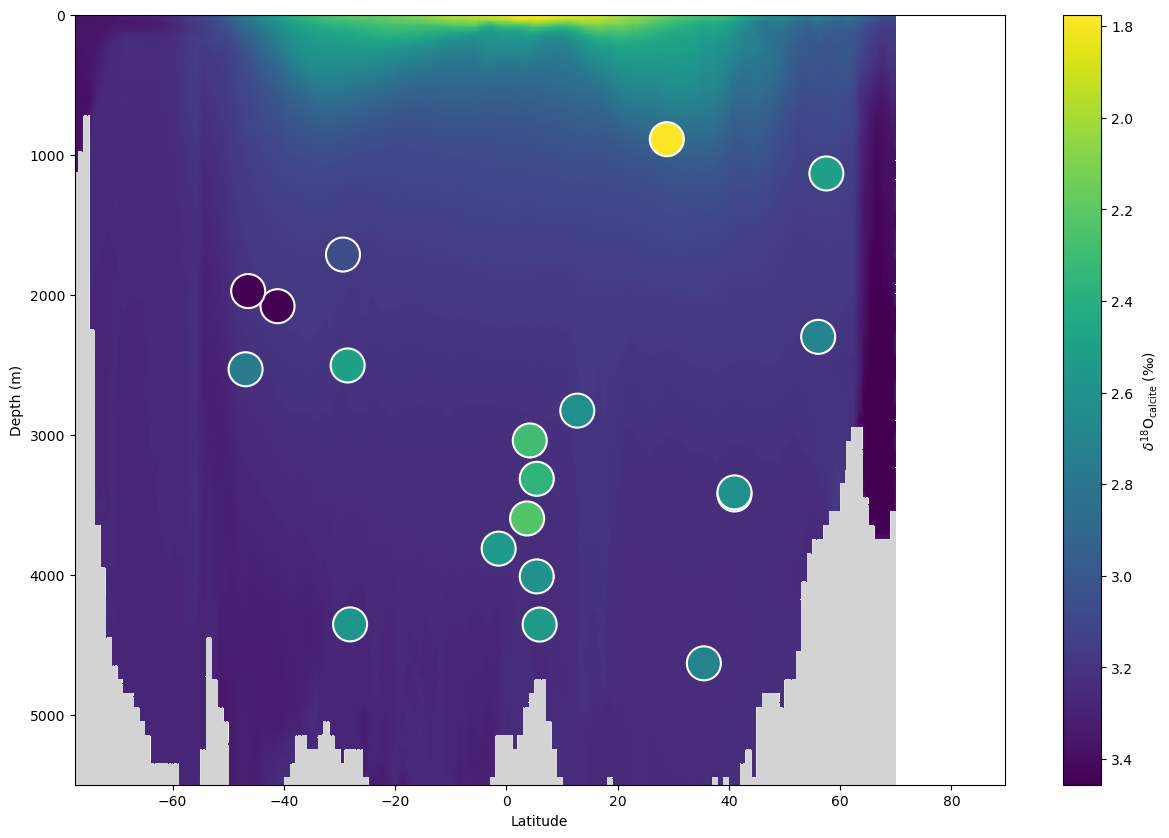

In [4]:
# Import necessary libraries
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
import numpy.ma as ma

# Read the netCDF file
nc_file = nc.Dataset(MODERN_D18O_PATH)

# Extract variables
d18o_GISS = nc_file.variables['d18o'][:]
depth_GISS = nc_file.variables['depth'][:]
lat_GISS = nc_file.variables['lat'][:]
lon_GISS = nc_file.variables['lon'][:]

d18o_plot_GISS, plot_lat_GISS, plot_depth_GISS = latdepthplot(lat_GISS, lon_GISS, depth_GISS, d18o_GISS, normalise=False)
modern_temp_plot, modern_plot_lat, modern_plot_depth = latdepthplot(lat_coords, lon_coords, depth_coords, temperature_grid_masked, normalise=False)

modern_lat, modern_depth, modern_temp, modern_d18O = interpolate_to_common_grid(modern_plot_lat, modern_plot_depth, modern_temp_plot, plot_lat_GISS, plot_depth_GISS, d18o_plot_GISS)

adjusted_array = - 0.224 * modern_temp + 3.26 + modern_d18O

# Create the plot
plt.figure(figsize=(15, 10))
shade_below_bathymetry(plt.gca(), modern_lat, modern_depth, adjusted_array)
plt.pcolormesh(modern_lat, modern_depth, adjusted_array, cmap='viridis_r', shading='auto')
scatter = plt.scatter(
    PLIOMIP2_d18O_comparison_table["Latitude"],
    PLIOMIP2_d18O_comparison_table["Water depth (m)"],
    c=PLIOMIP2_d18O_comparison_table["OC3 d18O"],
    cmap='viridis_r',
    s=600,
    edgecolors='white',
    linewidths=1.5,
    zorder=3,
)
# Use LaTeX scientific form for d18O_calcite
cbar = plt.colorbar(label=r'$\delta^{18}\mathrm{O}_{\mathrm{calcite}}$ (‰)')
cbar.ax.invert_yaxis()
plt.xlabel('Latitude')
plt.ylabel('Depth (m)')
plt.gca().invert_yaxis()  # Invert depth axis
plt.gca().set_ylim(np.nanmax(modern_depth), np.nanmin(modern_depth))
plt.show()

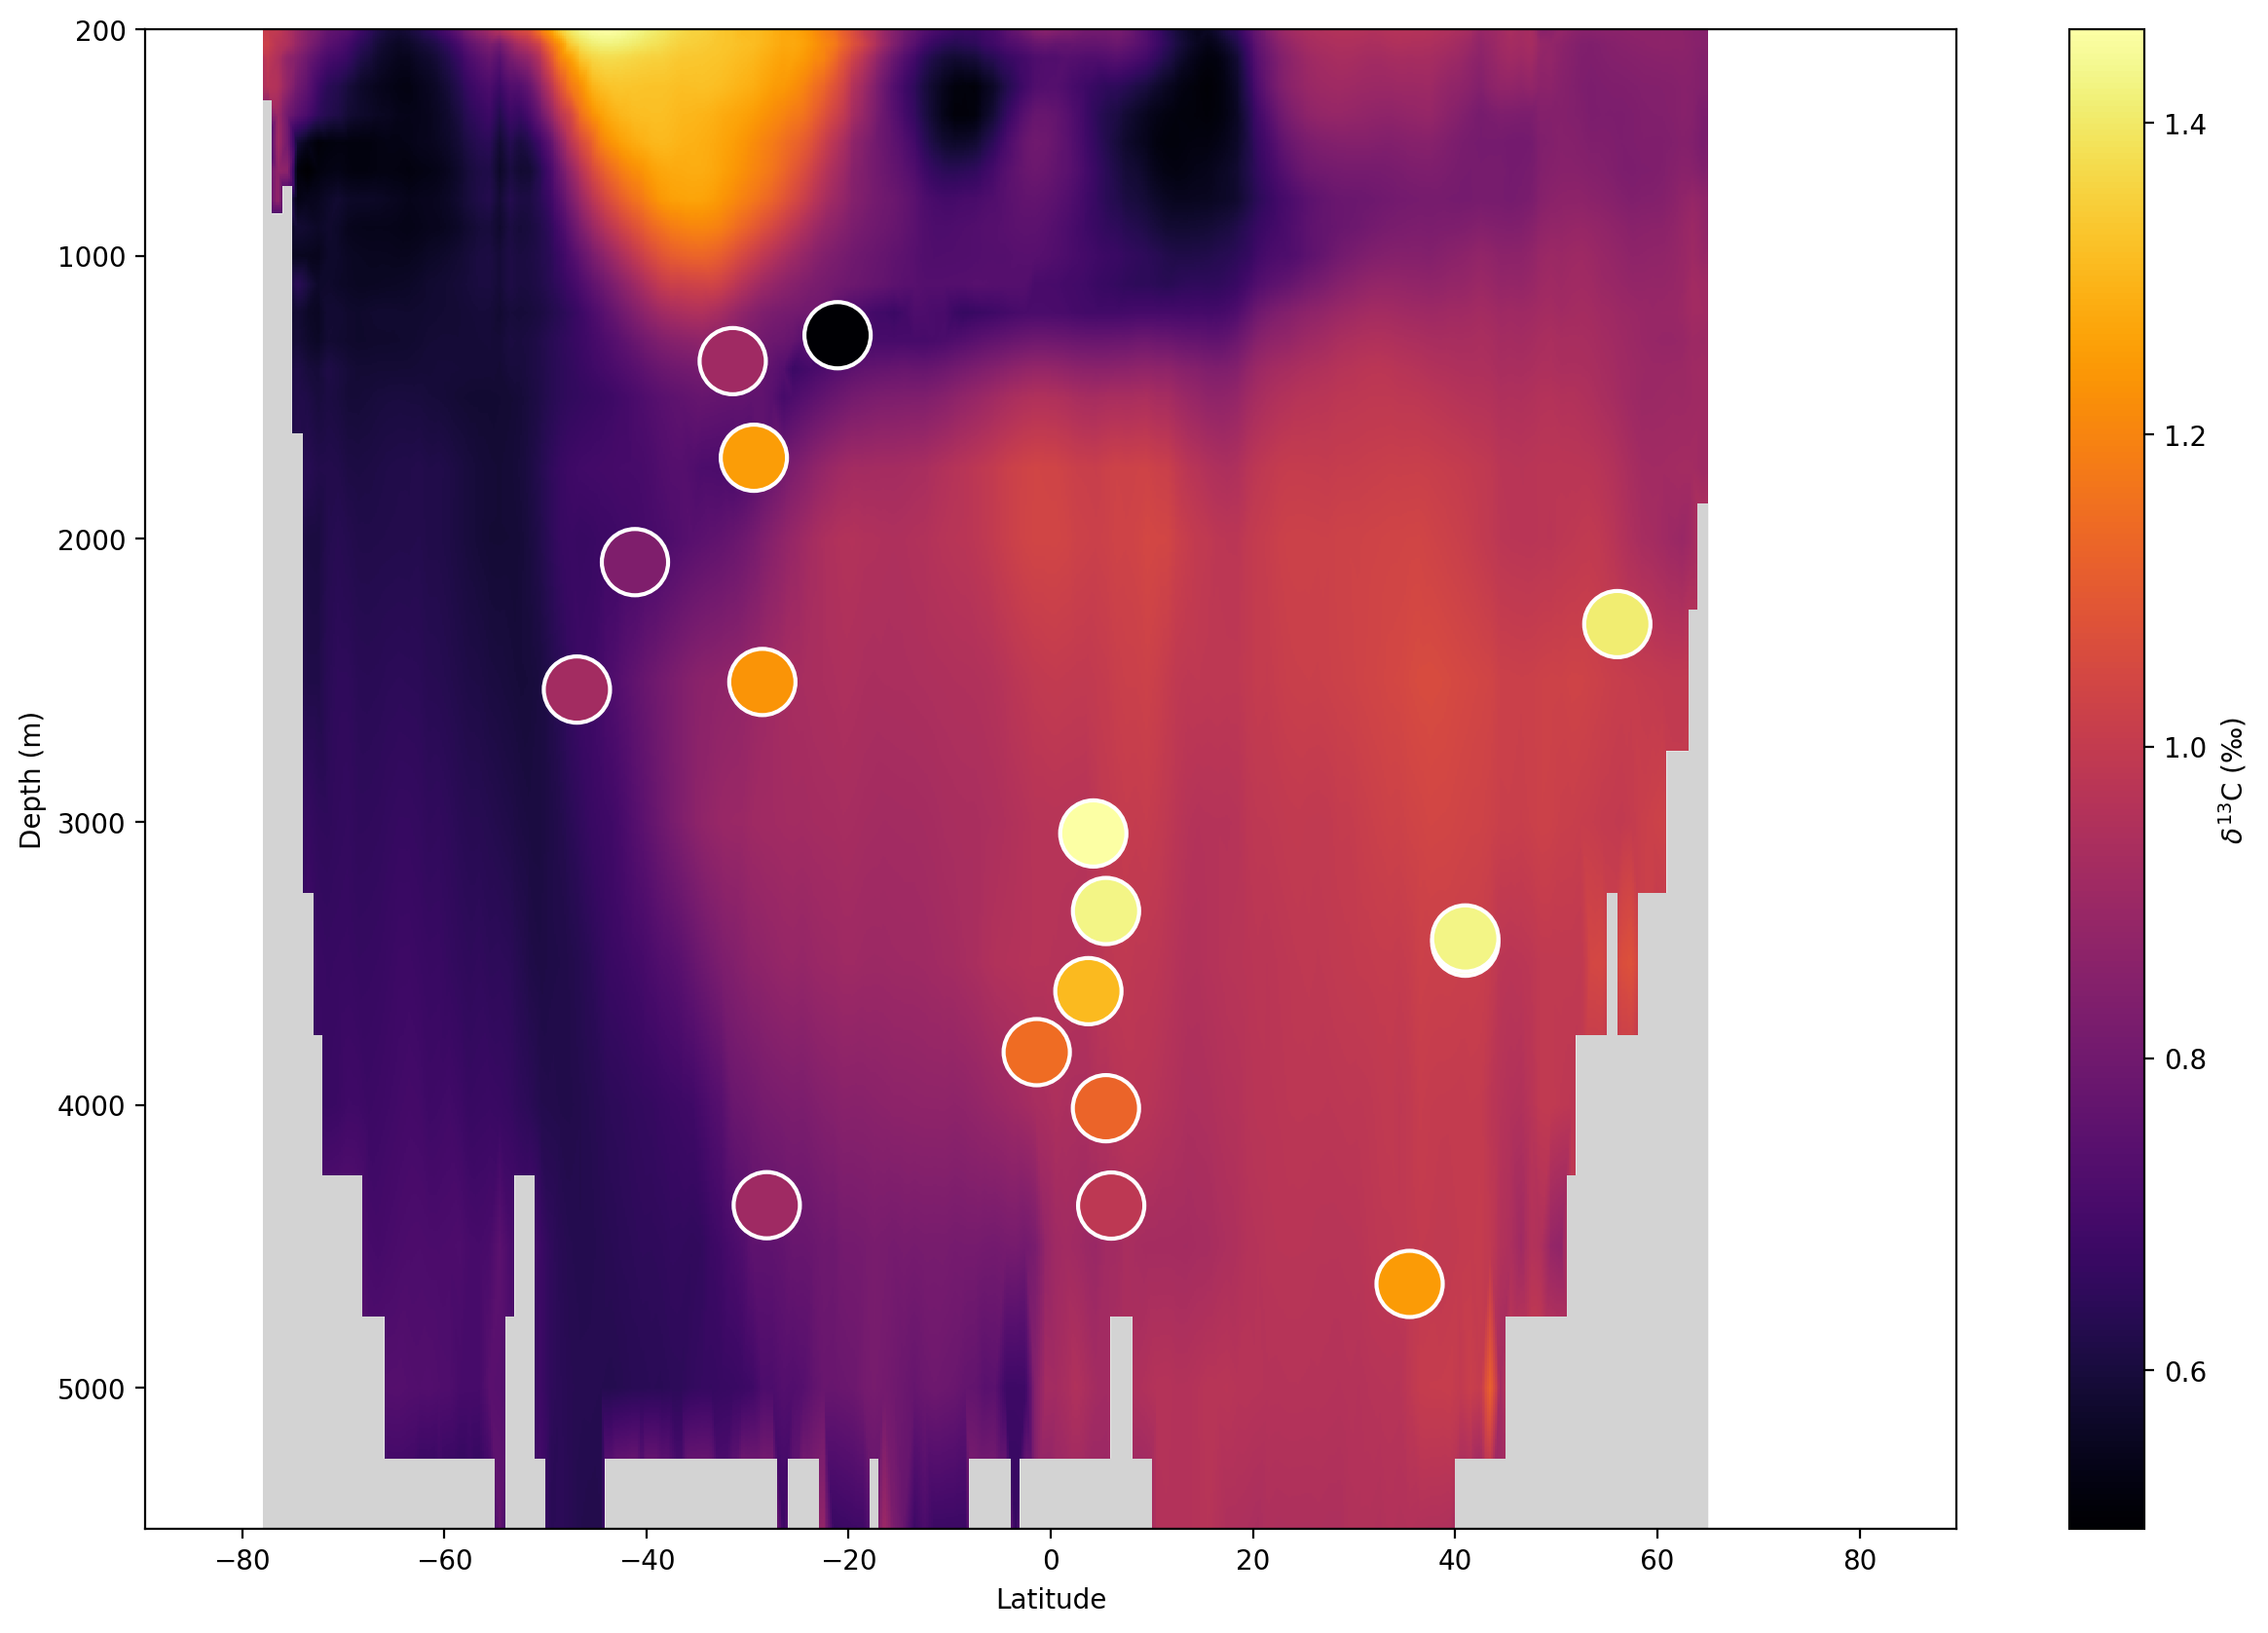

In [5]:
d13C_modern, lat_modern, depth_modern = latdepthplot(mo_lat, mo_lon, mo_depth, mo_d13C_masked, normalise=False, trimtop = False)

plt.figure(figsize=(15, 10), dpi=200)
shade_below_bathymetry(plt.gca(), lat_modern, depth_modern, d13C_modern)
plt.pcolormesh(lat_modern, depth_modern, d13C_modern, cmap='inferno', shading='auto')

# Use LaTeX scientific form for d13C
cbar = plt.colorbar(label=r'$\delta^{13}\mathrm{C}$ (‰)')
plt.xlabel('Latitude')
plt.ylabel('Depth (m)')
plt.gca().invert_yaxis()
ax = plt.gca()
ax.set_ylim(depth_modern.max(), 200)   # sets limit AND inverts direction
top, bottom = ax.get_ylim()           # e.g. (max_depth, 200)
ticks = [t for t in ax.get_yticks() if bottom <= t <= top]  # only ticks in-range
ticks.append(200)
ax.set_yticks(sorted(set(ticks)))  # Invert depth axis
scatter = plt.scatter(
    PLIOMIP2_d13C_comparison_table["Latitude"],
    PLIOMIP2_d13C_comparison_table["Water depth (m)"],
    c=PLIOMIP2_d13C_comparison_table["OC3 d13C"],
    cmap='inferno',
    s=600,
    edgecolors='white',
    linewidths=1.5,
    zorder=3,
)
plt.show()


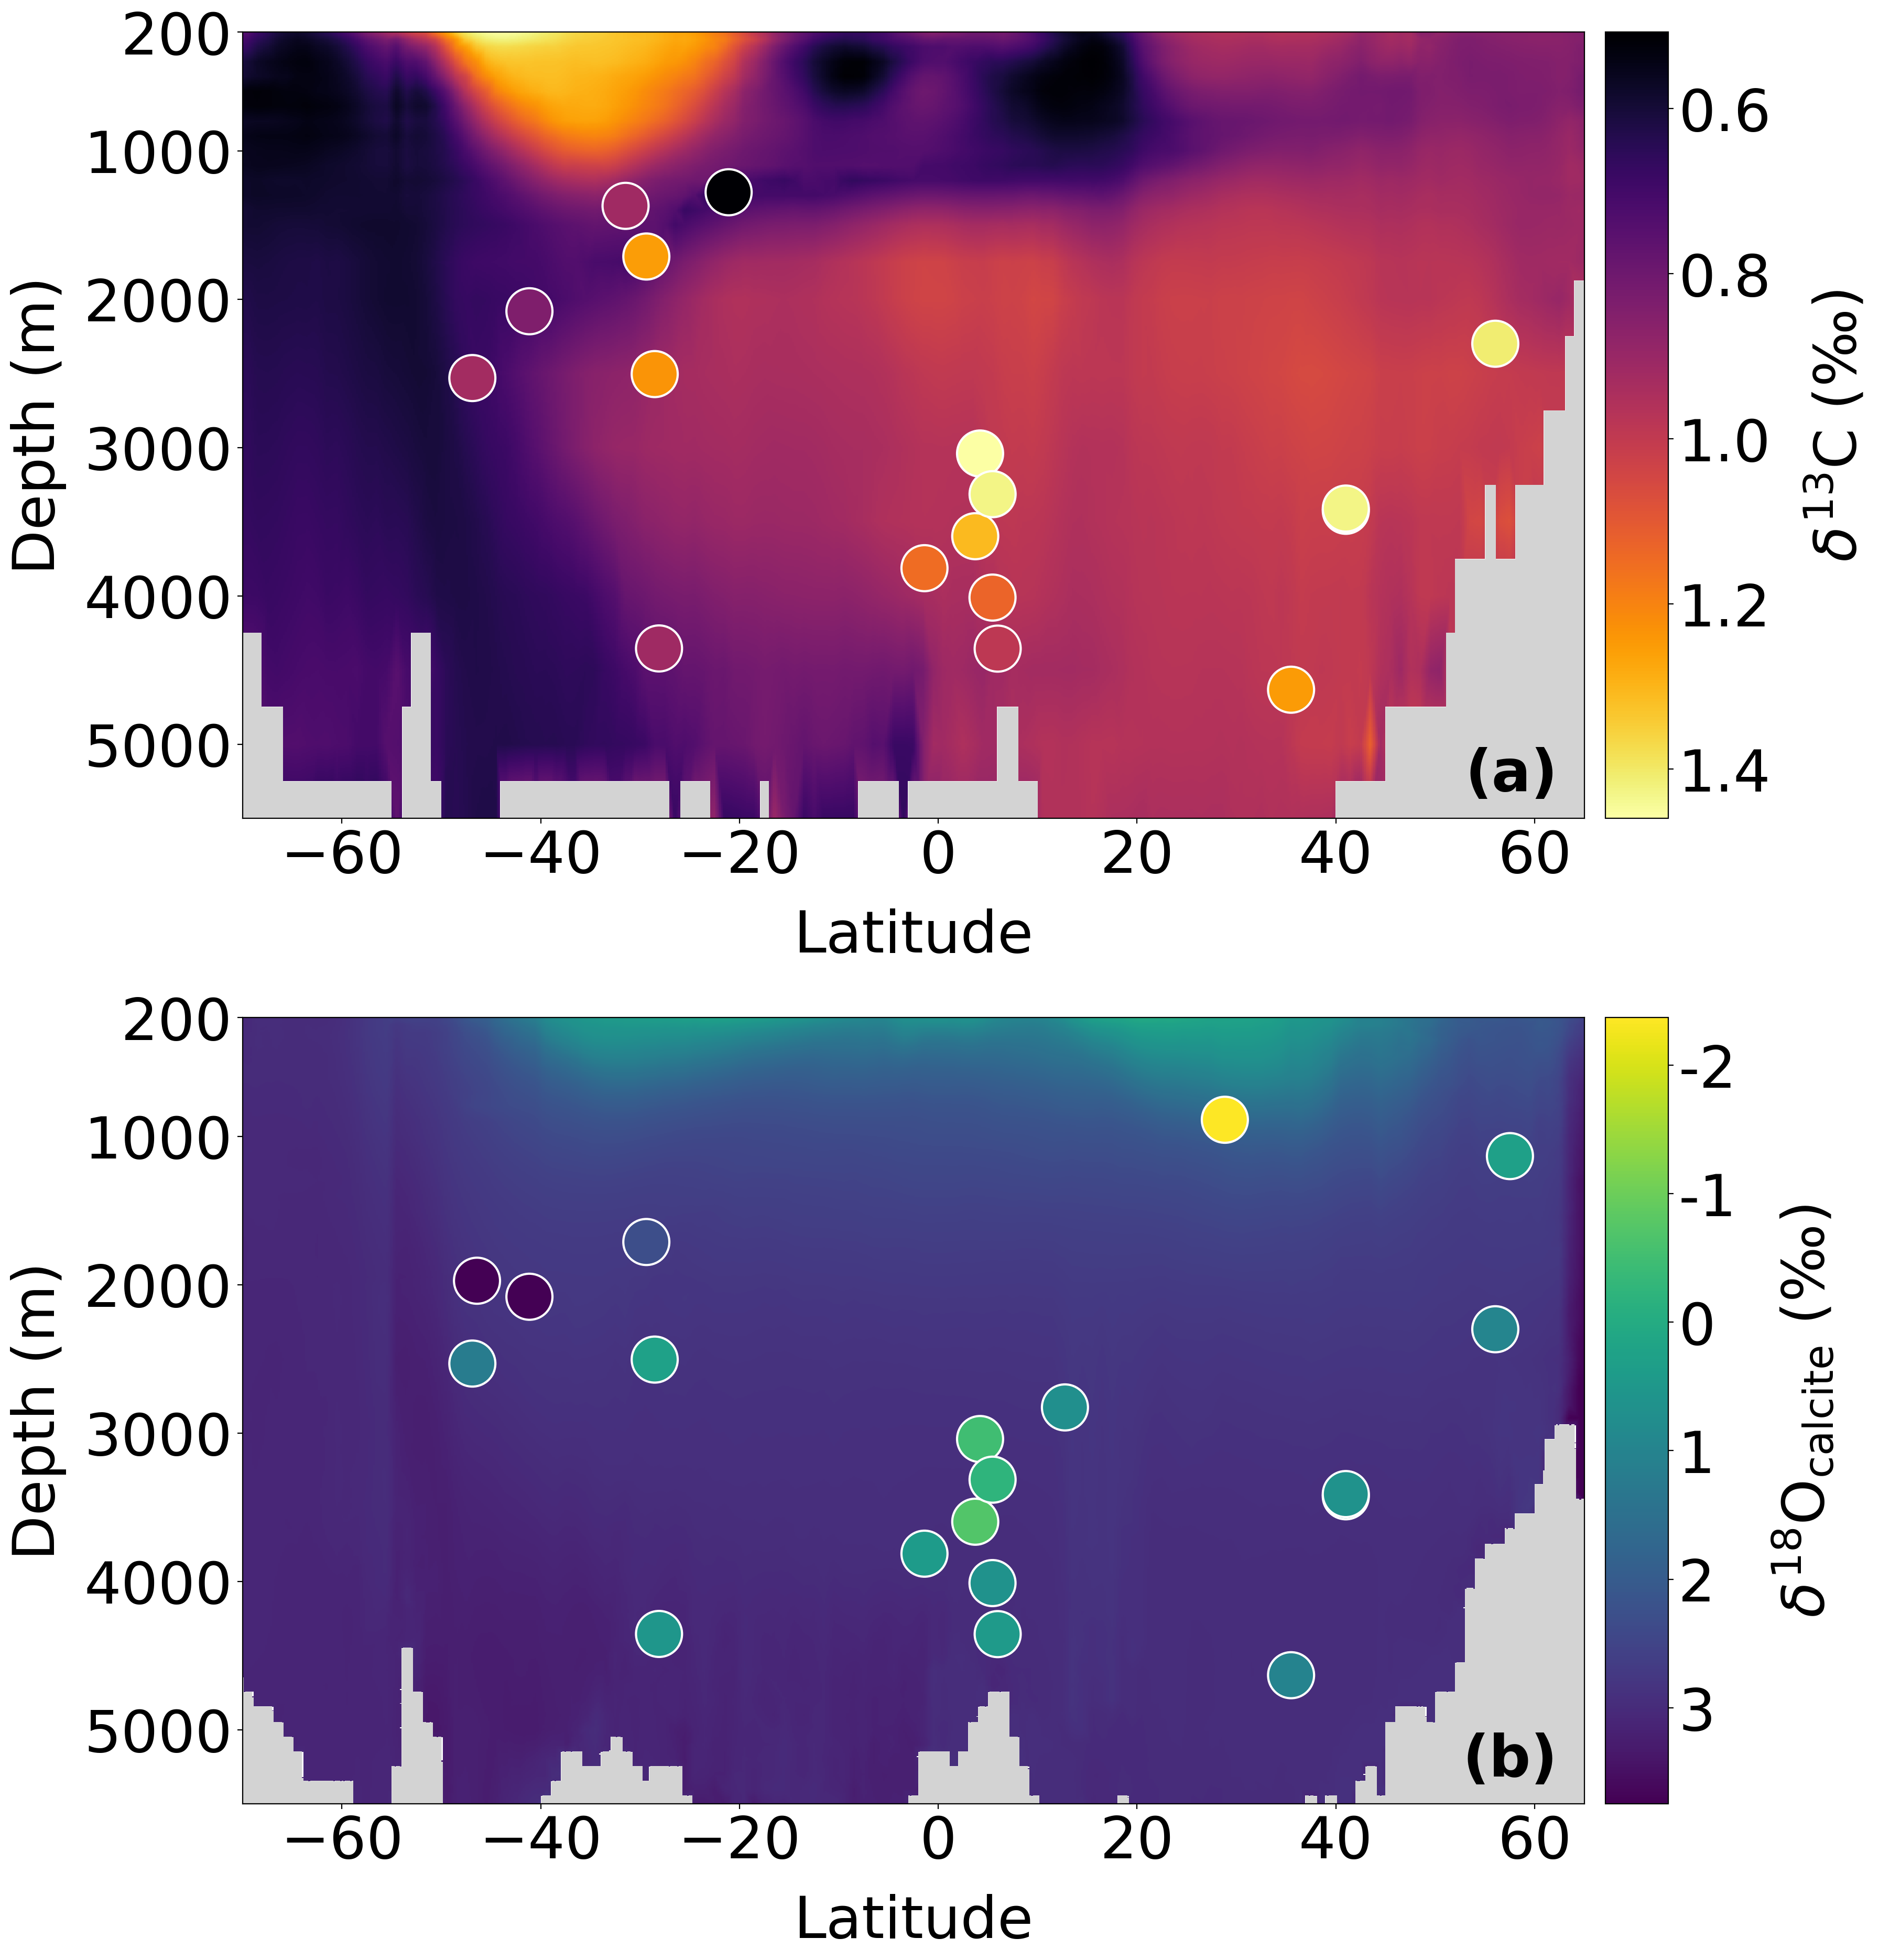

In [6]:
# Combined d18O and d13C figure
d13C_modern, lat_modern, depth_modern = latdepthplot(
    mo_lat, mo_lon, mo_depth, mo_d13C_masked, normalise=False, trimtop=False
)

lat_min, lat_max = -70, 65


def crop_lat_field(field, lat, depth, lat_min, lat_max):
    lat = np.asarray(lat, dtype=float)
    depth = np.asarray(depth, dtype=float)

    if lat.ndim == 2:
        lat_1d = lat[0, :]
        lat_on_columns = field.shape[1] == lat.shape[1]
    else:
        lat_1d = lat
        lat_on_columns = field.shape[1] == len(lat_1d)

    sel = (lat_1d >= lat_min) & (lat_1d <= lat_max)

    if lat_on_columns:
        field_out = field[:, sel]
        lat_out = lat[:, sel] if lat.ndim == 2 else lat_1d[sel]
        depth_out = depth[:, sel] if depth.ndim == 2 else depth
    else:
        field_out = field[sel, :]
        lat_out = lat[sel, :] if lat.ndim == 2 else lat_1d[sel]
        depth_out = depth[sel, :] if depth.ndim == 2 else depth

    return field_out, lat_out, depth_out


d13C_plot, lat_plot_d13C, depth_plot_d13C = crop_lat_field(
    d13C_modern, lat_modern, depth_modern, lat_min, lat_max,
)
d18O_plot, lat_plot_d18O, depth_plot_d18O = crop_lat_field(
    adjusted_array, modern_lat, modern_depth, lat_min, lat_max,
)

shared_depth_max = max(np.nanmax(depth_plot_d13C), np.nanmax(depth_plot_d18O))
depth_shallow = 200

import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 40,
    "axes.labelsize": 40,
    "xtick.labelsize": 40,
    "ytick.labelsize": 40,
})

fig = plt.figure(figsize=(20, 20), dpi=200)
# Equal-width maps; keep just enough room for Depth labels, not large empty gaps
ax_d13C = fig.add_axes([0.23, 0.57, 0.64, 0.375])
ax_d18O = fig.add_axes([0.23, 0.10, 0.64, 0.375])
cax_d13C = fig.add_axes([0.88, 0.57, 0.03, 0.375])
cax_d18O = fig.add_axes([0.88, 0.10, 0.03, 0.375])

# Top panel: d13C
shade_below_bathymetry(ax_d13C, lat_plot_d13C, depth_plot_d13C, d13C_plot)
pc_d13C = ax_d13C.pcolormesh(
    lat_plot_d13C, depth_plot_d13C, d13C_plot, cmap='inferno', shading='auto'
)
ax_d13C.scatter(
    PLIOMIP2_d13C_comparison_table["Latitude"],
    PLIOMIP2_d13C_comparison_table["Water depth (m)"],
    c=PLIOMIP2_d13C_comparison_table["OC3 d13C"],
    cmap='inferno',
    s=1000,
    edgecolors='white',
    linewidths=1.5,
    zorder=3,
)
ax_d13C.set_xlabel('Latitude', labelpad=16)
ax_d13C.set_ylabel('Depth (m)', labelpad=12)
ax_d13C.set_xlim(lat_min, lat_max)
ax_d13C.invert_yaxis()
ax_d13C.set_ylim(shared_depth_max, depth_shallow)
top, bottom = ax_d13C.get_ylim()
ticks = [t for t in ax_d13C.get_yticks() if bottom <= t <= top]
ticks.append(depth_shallow)
ax_d13C.set_yticks(sorted(set(ticks)))
cbar_d13C = fig.colorbar(pc_d13C, cax=cax_d13C)
cbar_d13C.set_label(r'$\delta^{13}\mathrm{C}$ (‰)', labelpad=24)
cbar_d13C.ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(0.2))
cbar_d13C.ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.1f'))
cbar_d13C.ax.invert_yaxis()

# Bottom panel: d18O
shade_below_bathymetry(ax_d18O, lat_plot_d18O, depth_plot_d18O, d18O_plot)
pc_d18O = ax_d18O.pcolormesh(
    lat_plot_d18O, depth_plot_d18O, d18O_plot, cmap='viridis_r', shading='auto'
)
ax_d18O.scatter(
    PLIOMIP2_d18O_comparison_table["Latitude"],
    PLIOMIP2_d18O_comparison_table["Water depth (m)"],
    c=PLIOMIP2_d18O_comparison_table["OC3 d18O"],
    cmap='viridis_r',
    s=1000,
    edgecolors='white',
    linewidths=1.5,
    zorder=3,
)
ax_d18O.set_xlabel('Latitude', labelpad=16)
ax_d18O.set_ylabel('Depth (m)', labelpad=12)
ax_d18O.set_xlim(lat_min, lat_max)
ax_d18O.invert_yaxis()
ax_d18O.set_ylim(shared_depth_max, depth_shallow)
top, bottom = ax_d18O.get_ylim()
ticks = [t for t in ax_d18O.get_yticks() if bottom <= t <= top]
ticks.append(depth_shallow)
ax_d18O.set_yticks(sorted(set(ticks)))
cbar_d18O = fig.colorbar(pc_d18O, cax=cax_d18O)
cbar_d18O.set_label(r'$\delta^{18}\mathrm{O}_{\mathrm{calcite}}$ (‰)', labelpad=24)
cbar_d18O.ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(1))
cbar_d18O.ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.0f'))
cbar_d18O.ax.invert_yaxis()

for ax, label in zip([ax_d13C, ax_d18O], ["(a)", "(b)"]):
    ax.text(
        0.98, 0.02, label,
        transform=ax.transAxes,
        ha="right", va="bottom",
        fontsize=40, fontweight="bold",
        zorder=20,
    )

fig.savefig(FIG_DIR / "modern_OC3_d18O_d13C.png", dpi=300, bbox_inches="tight")
plt.show()
